# Time series Classification
This notebook contains a comprehensive workflow for time series classification of ECG data to detect ischemic events. 

It includes:

- Data loading and preprocessing, including label generation and feature engineering.
- Multiple classification models: Logistic Regression, Support Vector Machine (SVM), Gradient Boosting, and Random Forest, with hyperparameter tuning and evaluation (accuracy, ROC, confusion matrix, etc.).
- Extraction of time series motifs and anomalies using matrix profiles and motif discovery.
- Feature extraction from ECG signals, including morphology and rhythm features.
- Classification using features derived from motifs and matrix profiles.
- Shapelet-based time series classification using tslearn, including visualization of learned shapelets and their locations in the ECG signals.
- Visualizations for model performance, feature importance, and motif/shapelet analysis.

The notebook is structured to compare traditional feature-based classifiers with advanced time series methods, providing both code and visual insights for each step.

In [1]:
import sys
import os
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), "../.."))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)
import pandas as pd
from src.utils.labels_binary_classification import generate_ischemic_labels
import numpy as np
from tslearn.shapelets import LearningShapelets
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from tslearn.shapelets import grabocka_params_to_shapelet_size_dict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier


import matplotlib.pyplot as plt

from tslearn.preprocessing import TimeSeriesScalerMinMax

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    RocCurveDisplay
)

import stumpy

PROFILE_PATH = "../../data/processed/time_series_features.pkl"
DIAG_PATH = "../../data/raw/heart_diagnoses_1.csv"
LABELS_OUT = "../../data/processed/subject_to_labels_ischemic.csv"

df = pd.read_pickle(PROFILE_PATH)
df["subject_id"] = df["subject_id"].astype(str)

print("Patient profile loaded:", df.shape)

labels_df = generate_ischemic_labels(
    diagnoses_path=DIAG_PATH,
    output_path=LABELS_OUT
)
labels_df["subject_id"] = labels_df["subject_id"].astype(str)  # Ensure matching types

print("Labels generated:")
print(labels_df["label_ischemic"].value_counts())

# Remove ICD-derived features to avoid data leakage
ICD_MACRO_COLS = [
    "ACS_acute_ischemic",
    "Chronic_ischemic",
    "Heart_failure",
    "Valvular_nonrheumatic",
    "Myocarditis_or_cardiomyopathy",
    "Pericardial_disease",
    "Endocarditis",
    "Cardiac_arrest",
    "Arrhythmias_or_conduction",
]

clf_df = df.drop(columns=[c for c in ICD_MACRO_COLS if c in df.columns])

# Merge labels with features
clf_df = clf_df.merge(labels_df[["subject_id", "label_ischemic"]], on="subject_id", how="inner")

print("Final classification dataset:", clf_df.shape)
print(f"Label distribution:\n{clf_df['label_ischemic'].value_counts()}")

# Convert 'gender' to boolean 
clf_df['gender'] = clf_df['gender'].map({'M': 1, 'F': 0})

clf_df

Patient profile loaded: (1276, 17)
Labels generated:
label_ischemic
0    2374
1    2018
Name: count, dtype: int64
Final classification dataset: (1276, 18)
Label distribution:
label_ischemic
0    656
1    620
Name: count, dtype: int64


,subject_id,Heart_Rate,SDNN,RMSSD,pNN50,r_amplitude,qrs_duration_ms,template_kurtosis,mean_t_wave_amplitude,mean_qt_interval_sec,mean_qtc_bazett,smoothed_V5,hadm_id,icd_code,long_title,gender,age,label_ischemic
0,10000980,85.510689,286.859907,390.282415,91.666667,0.853594,26.0,3.216454,1.305782,0.305000,0.373318,"[0.1900969337148387, 0.32999500991864766, 0.43...",29654838,I50,Heart failure,0,75,1
1,10000980,85.510689,286.859907,390.282415,91.666667,0.853594,26.0,3.216454,1.305782,0.305000,0.373318,"[0.1900969337148387, 0.32999500991864766, 0.43...",26913865,I21,Acute myocardial infarction,0,75,1
2,10004457,99.645704,5.974549,5.264436,0.000000,2.010598,22.0,7.033469,0.977192,0.202800,0.266090,"[-0.0766542576911958, -0.0834740406359752, -0....",28723315,I35,Nonrheumatic aortic valve disorders,1,66,0
3,10007058,58.227302,25.549516,29.470324,11.111111,2.623017,16.0,15.739641,2.045931,0.131556,0.129329,"[0.6220325944564501, 0.6245372941308491, 0.626...",22954658,I21,Acute myocardial infarction,1,48,1
4,10018684,139.919440,5.261146,7.708993,0.000000,1.305711,30.0,3.321043,1.450027,0.184818,0.283771,"[-0.2086264189594731, -0.2883589310107829, -0....",26649049,I48,Atrial fibrillation and flutter,1,48,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1271,19969326,120.832401,96.780663,132.479521,61.111111,1.484262,22.0,3.262440,0.600172,0.173333,0.252980,"[0.23258029095280755, 0.16928714122752297, 0.1...",20407284,I48,Atrial fibrillation and flutter,0,71,0
1272,19969991,94.996833,6.684737,8.485281,0.000000,1.262466,36.0,4.218535,1.063819,0.190533,0.234068,"[0.24080381670572953, 0.23087897419110062, 0.2...",22950880,I48,Atrial fibrillation and flutter,0,62,0
1273,19970101,82.209106,48.211074,40.930836,23.076923,1.373064,28.0,5.345187,2.012527,0.226615,0.257202,"[-0.045459704865495186, -0.05145871081320045, ...",28958051,I21,Acute myocardial infarction,1,87,1
1274,19985259,71.989529,164.703591,294.440486,36.363636,2.221755,18.0,9.305232,1.225135,0.142727,0.159277,"[-0.23222132335096257, -0.26604865236560576, -...",23988340,I47,Paroxysmal tachycardia,1,70,0


In [2]:
def evaluate_binary(model, Xtr, ytr, Xte, yte):
    """
    Evaluate a binary classification model on training and test data.

    Parameters:
        model: Fitted classifier with predict and predict_proba methods (e.g., scikit-learn estimator).
        Xtr: Training features (array-like or DataFrame).
        ytr: Training labels (array-like or Series).
        Xte: Test features (array-like or DataFrame).
        yte: Test labels (array-like or Series).

    Returns:
        results: dict
            Dictionary with accuracy, balanced accuracy, precision, recall, F1, and ROC-AUC for both train and test sets.
        tuple:
            (ytr_pred, yte_pred, ytr_proba, yte_proba)
            - ytr_pred: Predicted class labels for training set.
            - yte_pred: Predicted class labels for test set.
            - ytr_proba: Predicted probabilities for positive class (train).
            - yte_proba: Predicted probabilities for positive class (test).
    """
    # Predict class labels (0/1) for train and test sets
    ytr_pred = model.predict(Xtr)
    yte_pred = model.predict(Xte)

    # Predict probabilities for ROC-AUC calculation
    ytr_proba = model.predict_proba(Xtr)[:, 1]
    yte_proba = model.predict_proba(Xte)[:, 1]

    # Collect evaluation metrics for both train and test sets
    results = {
        "train_accuracy": accuracy_score(ytr, ytr_pred),
        "test_accuracy": accuracy_score(yte, yte_pred),
        "train_balanced_accuracy": balanced_accuracy_score(ytr, ytr_pred),
        "test_balanced_accuracy": balanced_accuracy_score(yte, yte_pred),
        "train_precision": precision_score(ytr, ytr_pred),
        "test_precision": precision_score(yte, yte_pred),
        "train_recall": recall_score(ytr, ytr_pred),
        "test_recall": recall_score(yte, yte_pred),
        "train_f1": f1_score(ytr, ytr_pred),
        "test_f1": f1_score(yte, yte_pred),
        "train_roc_auc": roc_auc_score(ytr, ytr_proba),
        "test_roc_auc": roc_auc_score(yte, yte_proba),
    }
    # Return metrics and all predictions/probabilities for further analysis
    return results, (ytr_pred, yte_pred, ytr_proba, yte_proba)

## Features classification

## Logistic Regression

In [3]:


TARGET = "label_ischemic"
DROP_COLS_METADATA = ['subject_id', 'hadm_id', 'smoothed_V5', 'long_title', 'icd_code', 'pNN50', 'SDNN']

# Fix: flatten the list so all columns are passed as a single list
X = clf_df.drop(columns=[TARGET] + DROP_COLS_METADATA)
y = clf_df[TARGET].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30, # Splling the dataset in 70% training and 30% test
    stratify=y,
    random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train label distribution:\n", y_train.value_counts(normalize=True))
print("Test  label distribution:\n", y_test.value_counts(normalize=True))

Train: (893, 10)  Test: (383, 10)
Train label distribution:
 label_ischemic
0    0.513998
1    0.486002
Name: proportion, dtype: float64
Test  label distribution:
 label_ischemic
0    0.51436
1    0.48564
Name: proportion, dtype: float64


In [4]:
from sklearn.model_selection import GridSearchCV

# Define the parameter grid for LogisticRegression
param_grid = {
    'model__C': [0.01, 0.1, 1.0, 10.0, 100.0],
    'model__penalty': ['l2'],
    'model__solver': ['lbfgs', 'liblinear'],
    'model__class_weight': ['balanced', None],
    'model__max_iter': [1000, 2000,3000,5000]
}

# Create the pipeline as before
lr_clf = Pipeline(steps=[
    ("model", LogisticRegression(random_state=42))
])

# Set up GridSearchCV
grid_search = GridSearchCV(
    lr_clf,
    param_grid,
    cv=5,
    scoring='balanced_accuracy',
    n_jobs=-1,
    verbose=2
)

# Fit the grid search
grid_search.fit(X_train, y_train)

print("Best parameters found:", grid_search.best_params_)
print("Best balanced accuracy:", grid_search.best_score_)

Fitting 5 folds for each of 80 candidates, totalling 400 fits


/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and w

[CV] END model__C=0.01, model__class_weight=balanced, model__max_iter=1000, model__penalty=l2, model__solver=lbfgs; total time=   0.0s
[CV] END model__C=0.01, model__class_weight=balanced, model__max_iter=1000, model__penalty=l2, model__solver=lbfgs; total time=   0.0s
[CV] END model__C=0.01, model__class_weight=balanced, model__max_iter=1000, model__penalty=l2, model__solver=lbfgs; total time=   0.0s
[CV] END model__C=0.01, model__class_weight=balanced, model__max_iter=2000, model__penalty=l2, model__solver=lbfgs; total time=   0.0s
[CV] END model__C=0.01, model__class_weight=balanced, model__max_iter=2000, model__penalty=l2, model__solver=lbfgs; total time=   0.0s
[CV] END model__C=0.01, model__class_weight=balanced, model__max_iter=2000, model__penalty=l2, model__solver=lbfgs; total time=   0.0s
[CV] END model__C=0.01, model__class_weight=balanced, model__max_iter=2000, model__penalty=l2, model__solver=liblinear; total time=   0.0s
[CV] END model__C=0.01, model__class_weight=balance

/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and w

In [5]:
# Build and fit a new pipeline using the best hyperparameters found by grid_search
best_lr_clf = Pipeline(steps=[
    ("model", LogisticRegression(
        random_state=42,
        C=grid_search.best_params_["model__C"],
        penalty=grid_search.best_params_["model__penalty"],
        solver=grid_search.best_params_["model__solver"],
        class_weight=grid_search.best_params_["model__class_weight"],
        max_iter=grid_search.best_params_["model__max_iter"]
    ))
])
best_lr_clf.fit(X_train, y_train)

# Evaluate the optimized logistic regression model on train and test sets
lr_results, (y_train_pred, y_test_pred, y_train_proba, y_test_proba) = evaluate_binary(
    best_lr_clf, X_train, y_train, X_test, y_test
)

# Display the evaluation metrics in sorted order
pd.Series(lr_results).sort_index()

/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


test_accuracy              0.548303
test_balanced_accuracy     0.548155
test_f1                    0.538667
test_precision             0.534392
test_recall                0.543011
test_roc_auc               0.531303
train_accuracy             0.587906
train_balanced_accuracy    0.586955
train_f1                   0.566038
train_precision            0.579710
train_recall               0.552995
train_roc_auc              0.608139
dtype: float64

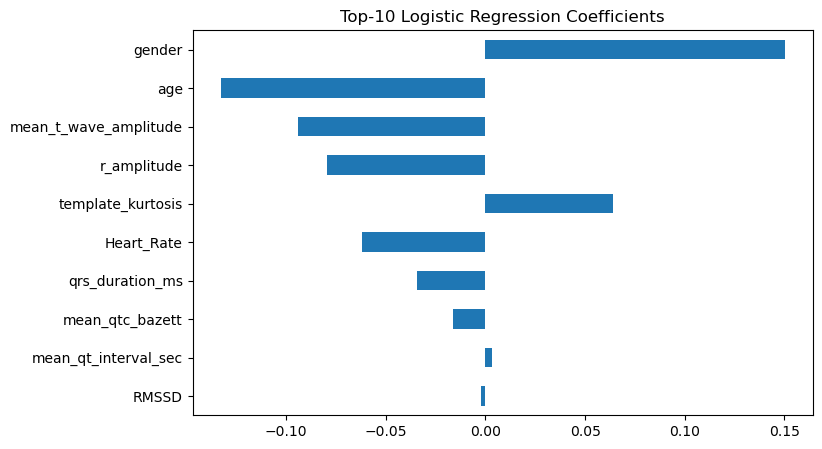

In [6]:
# Extract and visualize the most important features from the trained logistic regression model

# Get the coefficients from the fitted logistic regression model
coef = best_lr_clf.named_steps["model"].coef_[0]

# Create a sorted Series of coefficients by absolute value (most influential features first)
coef_df = (
    pd.Series(coef, index=X.columns)
    .sort_values(key=np.abs, ascending=False)
)

# Display the top 10 most important coefficients
coef_df.head(10)

# Plot the top 10 coefficients as a horizontal bar chart
plt.figure(figsize=(8, 5))
coef_df.head(10).plot(kind="barh")
plt.title("Top-10 Logistic Regression Coefficients")
plt.gca().invert_yaxis()  # Highest coefficient at the top
plt.show()

The Logistic Regression model relies heavily on patient metadata (Gender, Age) to make decisions, with demographic factors outweighing physiological signal features. While the model successfully identified T-wave depression/inversion (via the negative coefficient for T-wave amplitude) as a risk factor, the counter-intuitive weighting of Age suggests potential biases in the training data distribution.

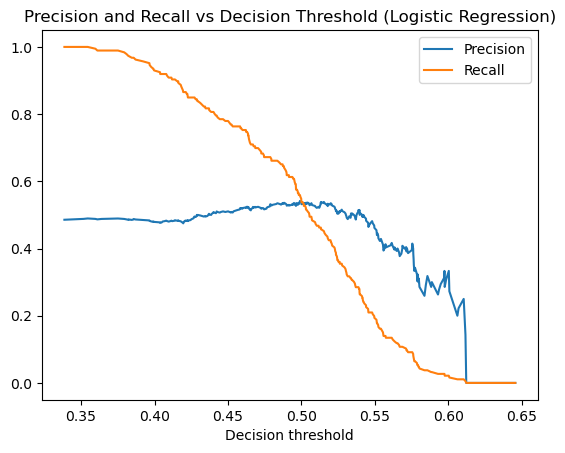

In [7]:
from sklearn.metrics import precision_recall_curve

# Compute precision, recall, and thresholds for different decision boundaries
prec, rec, thr = precision_recall_curve(y_test, y_test_proba)

# Plot how precision and recall change as the decision threshold varies
plt.plot(thr, prec[:-1], label="Precision")
plt.plot(thr, rec[:-1], label="Recall")
plt.title("Precision and Recall vs Decision Threshold (Logistic Regression)")
plt.xlabel("Decision threshold")
plt.legend()
plt.show()

The Precision-Recall versus Decision Threshold plot for the Logistic Regression classifier illustrates the model's limited predictive capacity and poor calibration. The precision curve remains low throughout, starting around 0.49 and barely exceeding 0.55 at its peak, indicating that the model struggles to identify a reliable "safe zone" of confident predictions. At the default decision threshold of approximately 0.50, the precision and recall curves intersect, with both metrics stabilizing around 0.53–0.54, which aligns with the previously reported low F1-scores.

Most critically, the plot reveals significant instability at higher thresholds. Typically, precision should improve as the threshold increases and the model becomes more selective. However, in this case, the precision curve becomes jagged and drops sharply as the threshold approaches 0.60. This anomaly suggests that the model's highest-confidence predictions are frequently incorrect (False Positives), highlighting a fundamental failure of the linear decision boundary to isolate distinct ischemic cases. Furthermore, high recall (>0.90) is only achievable at very low thresholds (<0.40), forcing a trade-off where nearly half of all positive flags are false alarms. This confirms that there is no optimal operating point for this model.

In [8]:
from sklearn.model_selection import cross_val_score

# Perform 5-fold cross-validation using the best logistic regression model
# This provides a more robust estimate of model performance on unseen data
cv_scores_lr = cross_val_score(
    best_lr_clf,
    X_train,
    y_train,
    cv=5,
    scoring="balanced_accuracy"
)

# Print the mean and standard deviation of the balanced accuracy across folds
print("Logistic Regression - 5-fold CV balanced accuracy")
print(f"Mean = {cv_scores_lr.mean():.3f}")
print(f"Std  = {cv_scores_lr.std():.3f}")

/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


Logistic Regression - 5-fold CV balanced accuracy
Mean = 0.586
Std  = 0.033


/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and w

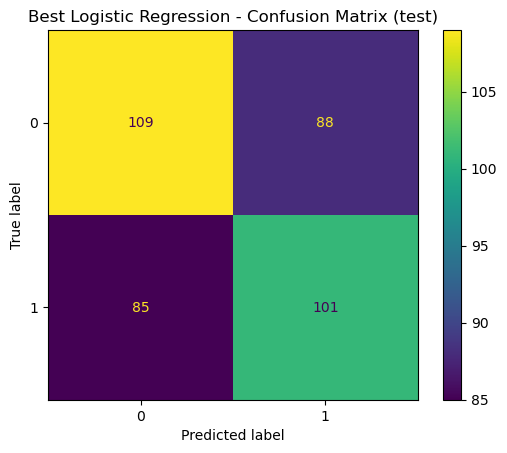


Classification report (test):
                  precision    recall  f1-score   support

Non-ischemic (0)       0.56      0.55      0.56       197
    Ischemic (1)       0.53      0.54      0.54       186

        accuracy                           0.55       383
       macro avg       0.55      0.55      0.55       383
    weighted avg       0.55      0.55      0.55       383



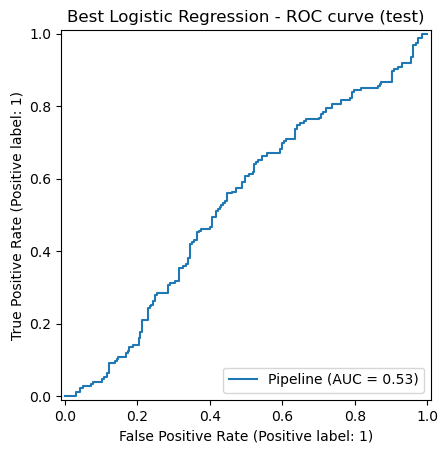

In [9]:
# Confusion matrix (test) for best logistic regression model
cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot()
plt.title("Best Logistic Regression - Confusion Matrix (test)")
plt.show()

print("\nClassification report (test):")
print(classification_report(y_test, y_test_pred, target_names=["Non-ischemic (0)", "Ischemic (1)"]))

# ROC curve (test) for best logistic regression model
RocCurveDisplay.from_estimator(best_lr_clf, X_test, y_test)
plt.title("Best Logistic Regression - ROC curve (test)")
plt.show()

The model achieved a precision of 0.56 and a recall of 0.55 for the non-ischaemic class. This indicates that while the model correctly identified 55\% of healthy subjects (specificity), it struggled to confidently differentiate them from ischaemic cases. Approximately 44\% of the subjects predicted as "healthy" were, in fact, ischaemic (false negatives), which limits the model's reliability in ruling out disease. For the critical ischaemic class, the model demonstrated a precision of 0.53 and a recall (sensitivity) of 0.54. A sensitivity of 0.54 implies that the classifier missed nearly half (46\%) of the actual ischaemia cases. Additionally, the low precision of 0.53 suggests that when the model flagged a patient as ischaemic, the likelihood of that diagnosis being correct was almost equivalent to chance.

## Support Vector Machine

In [10]:
from sklearn.svm import SVC

# Create the SVM classifier
svm_clf = SVC(
    kernel="rbf",          # Radial Basis Function kernel
    C=1.0,                 # Regularization parameter
    gamma="scale",        # Kernel coefficient
    probability=True,     # Enable probability estimates
    class_weight="balanced",
    random_state=42
)

svm_clf.fit(X_train, y_train)

svm_results, (y_train_pred_svm, y_test_pred_svm, y_train_proba_svm, y_test_proba_svm) = evaluate_binary(
    svm_clf, X_train, y_train, X_test, y_test
)

pd.Series(svm_results).sort_index()

test_accuracy              0.530026
test_balanced_accuracy     0.530989
test_f1                    0.538462
test_precision             0.514706
test_recall                0.564516
test_roc_auc               0.557994
train_accuracy             0.628219
train_balanced_accuracy    0.628869
train_f1                   0.630290
train_precision            0.609914
train_recall               0.652074
train_roc_auc              0.675592
dtype: float64

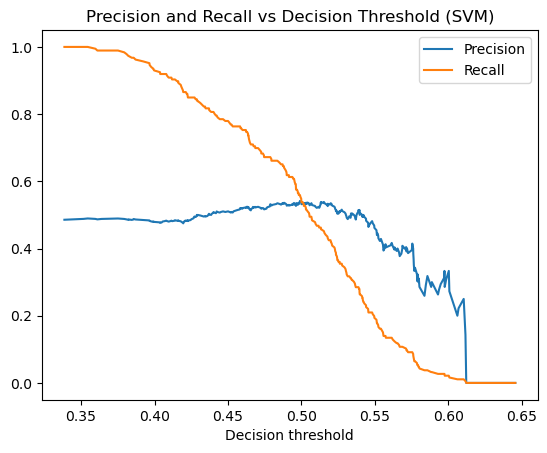

In [11]:
prec, rec, thr = precision_recall_curve(y_test, y_test_proba)

plt.plot(thr, prec[:-1], label="Precision")
plt.plot(thr, rec[:-1], label="Recall")
plt.title("Precision and Recall vs Decision Threshold (SVM)")
plt.xlabel("Decision threshold")
plt.legend()
plt.show()

The SVM classifier exhibits performance limitations nearly identical to the Logistic Regression model, confirming a failure to establish a robust separation boundary. The precision curve remains stagnant around $0.50$ for the majority of the decision range, never reaching a zone of high confidence. Crucially, increasing the decision threshold beyond $0.50$ does not improve precision as expected; instead, the metric becomes unstable and degrades, indicating that even the model's "strictest" predictions are unreliable. The intersection with recall occurs near the default threshold ($0.50$), where both metrics plateau at approximately $0.53$, offering only marginal improvement over a random baseline.

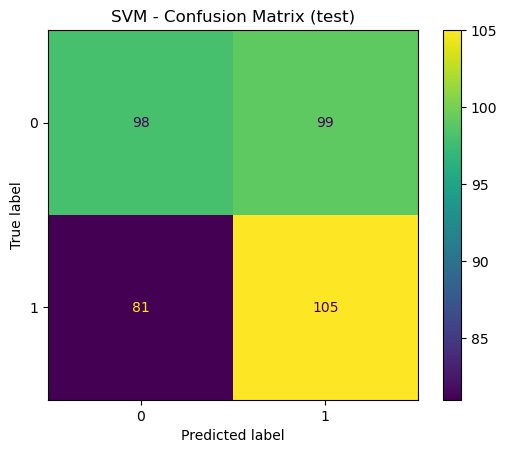


SVM Classification report (test):
                  precision    recall  f1-score   support

Non-ischemic (0)       0.55      0.50      0.52       197
    Ischemic (1)       0.51      0.56      0.54       186

        accuracy                           0.53       383
       macro avg       0.53      0.53      0.53       383
    weighted avg       0.53      0.53      0.53       383



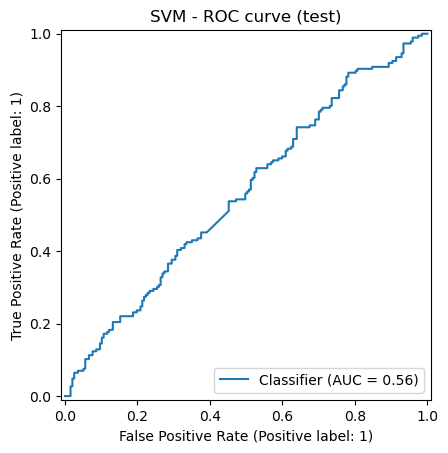

In [12]:
# Plot the confusion matrix for SVM (test)
cm_svm = confusion_matrix(y_test, y_test_pred_svm, labels=[0, 1])
disp_svm = ConfusionMatrixDisplay(confusion_matrix=cm_svm, display_labels=[0, 1])
disp_svm.plot()
plt.title("SVM - Confusion Matrix (test)")
plt.show()

print("\nSVM Classification report (test):")
print(classification_report(y_test, y_test_pred_svm, target_names=["Non-ischemic (0)", "Ischemic (1)"]))

# PLot the ROC curve for SVM (test)
RocCurveDisplay.from_predictions(y_test, y_test_proba_svm)
plt.title("SVM - ROC curve (test)")
plt.show()

The model exhibits a slight bias towards the positive class, achieving a Recall of $0.56$. This means the classifier correctly identified $56\%$ of actual Ischemic cases. However, the Precision is low at $0.51$, indicating that nearly half of the patients predicted as Ischemic were actually false positives. The model also struggled with the negative class, obtaining a Recall of $0.50$. This suggests that the classifier misdiagnosed $50\%$ of healthy (Non-ischemic) individuals as having the condition. The F1-scores, which are $0.52$ for Non-ischemic cases and $0.54$ for Ischemic cases, confirm that the model lacks robustness. While the SVM shows a marginal preference for detecting Ischemic cases over healthy ones, the overall accuracy of $0.53$ implies that the current decision boundary is ineffective, performing only slightly better than random chance.

## Gradient boosting Classifier

In [13]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier

# Define the hyperparameter grid for tuning the GradientBoostingClassifier.
# Each key corresponds to a parameter, and the list contains the values to try during grid search.
param_grid_gb = {
    'n_estimators': [100, 200, 300],      # Number of boosting stages (trees)
    'learning_rate': [0.01, 0.05, 0.1],  # Step size shrinkage used in update to prevent overfitting
    'max_depth': [3, 5, 6],              # Maximum depth of each tree
    'subsample': [0.8, 1.0],             # Fraction of samples used for fitting each base learner
    'min_samples_split': [2, 5, 10],     # Minimum number of samples required to split an internal node
    'min_samples_leaf': [1, 3, 5]        # Minimum number of samples required to be at a leaf node
}

# Initialize the base GradientBoostingClassifier with a fixed random seed for reproducibility.
gb_clf_base = GradientBoostingClassifier(random_state=42)

# Set up GridSearchCV to perform exhaustive search over the specified parameter grid.
# - cv=5: 5-fold cross-validation
# - scoring='balanced_accuracy': Use balanced accuracy as the evaluation metric
# - n_jobs=-1: Use all available CPU cores for parallel processing
# - verbose=2: Print progress messages during fitting
grid_search_gb = GridSearchCV(
    gb_clf_base,
    param_grid_gb,
    cv=5,
    scoring='balanced_accuracy',
    n_jobs=-1,
    verbose=2
)

# Fit the grid search to the training data to find the best hyperparameter combination.
grid_search_gb.fit(X_train, y_train)

# Output the best hyperparameters and the corresponding balanced accuracy score.
print("Best parameters found:", grid_search_gb.best_params_)
print("Best balanced accuracy:", grid_search_gb.best_score_)

# Retrieve the best estimator from the grid search and refit it on the full training set.
gb_best = grid_search_gb.best_estimator_
gb_best.fit(X_train, y_train)

# Evaluate the optimized Gradient Boosting model using the custom evaluation function.
gb_results, (gb_y_train_pred, gb_y_test_pred, gb_y_train_proba, gb_y_test_proba) = evaluate_binary(
    gb_best, X_train, y_train, X_test, y_test
)

# Display the evaluation metrics in sorted order for easier interpretation.
print(pd.Series(gb_results).sort_index())

Fitting 5 folds for each of 486 candidates, totalling 2430 fits
[CV] END learning_rate=0.01, max_depth=3, min_samples_leaf=1, min_samples_split=2, n_estimators=100, subsample=0.8; total time=   0.1s
[CV] END learning_rate=0.01, max_depth=3, min_samples_leaf=1, min_samples_split=2, n_estimators=100, subsample=0.8; total time=   0.1s
[CV] END learning_rate=0.01, max_depth=3, min_samples_leaf=1, min_samples_split=2, n_estimators=100, subsample=0.8; total time=   0.1s
[CV] END learning_rate=0.01, max_depth=3, min_samples_leaf=1, min_samples_split=2, n_estimators=100, subsample=0.8; total time=   0.1s
[CV] END learning_rate=0.01, max_depth=3, min_samples_leaf=1, min_samples_split=2, n_estimators=100, subsample=1.0; total time=   0.1s
[CV] END learning_rate=0.01, max_depth=3, min_samples_leaf=1, min_samples_split=2, n_estimators=100, subsample=1.0; total time=   0.1s
[CV] END learning_rate=0.01, max_depth=3, min_samples_leaf=1, min_samples_split=2, n_estimators=100, subsample=1.0; total time

In [14]:
# Perform 5-fold cross-validation using the best Gradient Boosting model.
# This provides a more robust estimate of model performance by evaluating it on different splits of the training data.
cv_scores_gb = cross_val_score(
    gb_best,           # The optimized GradientBoostingClassifier
    X_train,           # Training features
    y_train,           # Training labels
    cv=5,              # Number of cross-validation folds
    scoring="balanced_accuracy"  # Use balanced accuracy to account for class imbalance
)

# Print the mean and standard deviation of the balanced accuracy across the 5 folds.
print("GB - 5-fold CV balanced accuracy")
print(f"Mean = {cv_scores_gb.mean():.3f} | Std = {cv_scores_gb.std():.3f}")

GB - 5-fold CV balanced accuracy
Mean = 0.589 | Std = 0.024


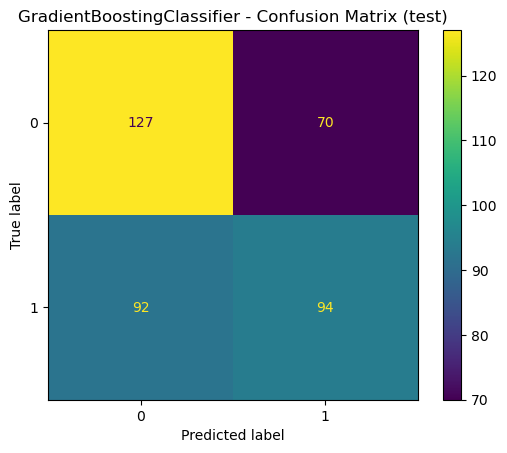


Gradient Boosting Classification report (test):
                  precision    recall  f1-score   support

Non-ischemic (0)       0.58      0.64      0.61       197
    Ischemic (1)       0.57      0.51      0.54       186

        accuracy                           0.58       383
       macro avg       0.58      0.58      0.57       383
    weighted avg       0.58      0.58      0.57       383



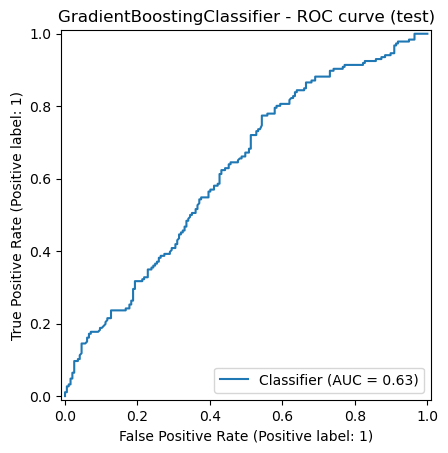

In [15]:
# Confusion matrix (test)
cm_rf = confusion_matrix(y_test, gb_y_test_pred, labels=[0, 1])
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=[0, 1])
disp_rf.plot()
plt.title("GradientBoostingClassifier - Confusion Matrix (test)")
plt.show() 
print("\nGradient Boosting Classification report (test):")
print(classification_report(y_test, gb_y_test_pred, target_names=["Non-ischemic (0)", "Ischemic (1)"]))
# ROC curve (test)
RocCurveDisplay.from_predictions(y_test, gb_y_test_proba)
plt.title("GradientBoostingClassifier - ROC curve (test)")
plt.show()

Based on the results, we can conclude that the model performed best on the negative class, achieving a Recall of $0.64$ and a Precision of $0.58$. This indicates that the model is relatively effective at accurate ruling out the disease in healthy patients, reflected in an F1-score of $0.61$. However, detecting the positive class remains challenging. While the Precision for ischemia is moderate at $0.57$—meaning that predictions for ischemia are correct $57\%$ of the time—the Recall is lower at $0.51$. This suggests that the model misses approximately $49\%$ of actual ischemic cases, resulting in a high rate of false negatives.In contrast to the results from the Support Vector Machine (SVM) and Logistic Regression, the Gradient Boosting model demonstrates a slightly superior predictive power with an overall accuracy of $0.58$. However, unlike the previous iteration, the performance is not perfectly balanced; there is a noticeable bias toward the non-ischemic class (F1-score $0.61$ vs $0.54$). Although the macro-averaged metrics ($0.58$) indicate moderate general capability, further optimization is clearly needed to enhance the sensitivity for clinical applications.

## Random Forest

In [16]:
from sklearn.ensemble import RandomForestClassifier

# Initialize a baseline Random Forest classifier with specific hyperparameters:
rf_clf = RandomForestClassifier(
    n_estimators=30,        # A moderate number of trees to reduce variance compared to a single decision tree
    criterion="gini",       # Use the Gini impurity to measure the quality of splits
    max_features=3,         # Randomly select 3 features at each split to introduce diversity among trees
    max_depth=4,            # Limit the maximum depth of each tree to prevent overfitting
    min_samples_split=2,    # Minimum number of samples required to split an internal node (default)
    min_samples_leaf=8,     # Minimum number of samples required at a leaf node for more stable and generalizable predictions
    bootstrap=True,         # Use bootstrap samples (sampling with replacement) to build each tree
    class_weight="balanced",# Adjust weights inversely proportional to class frequencies to handle class imbalance
    random_state=42         # Set random seed for reproducibility
)

In [17]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

# Define the hyperparameter search space for RandomizedSearchCV.
# Each key is a parameter name, and the values are lists or distributions to sample from.
param_dist = {
    "n_estimators": [30, 50, 100],           # Number of trees in the forest
    "max_depth": [2, 4, 6, 8, None],         # Maximum depth of each tree (None means unlimited)
    "max_features": [2, 3, "sqrt"],          # Number of features to consider at each split
    "min_samples_split": randint(2, 20),     # Minimum samples required to split a node (randomly sampled)
    "min_samples_leaf": randint(5, 20),      # Minimum samples required at a leaf node (randomly sampled)
    "bootstrap": [True],                     # Whether bootstrap samples are used when building trees
    "criterion": ["gini", "entropy"],        # Function to measure the quality of a split
    "class_weight": ["balanced", None]       # Adjust weights for class imbalance or use default
}

In [18]:
rf_base = rf_clf  # Use the previously defined baseline Random Forest as the starting estimator

# Set up RandomizedSearchCV to search for the best hyperparameters for the Random Forest.
# - estimator: the base Random Forest model
# - param_distributions: the hyperparameter search space defined above
# - n_iter=30: sample 30 different combinations of hyperparameters
# - scoring='balanced_accuracy': use balanced accuracy to account for class imbalance
# - cv=5: use 5-fold cross-validation for evaluation
# - n_jobs=-1: use all available CPU cores for parallel processing
# - random_state=42: ensure reproducibility of the search
rf_search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_dist,
    n_iter=30,
    scoring="balanced_accuracy",
    cv=5,
    n_jobs=-1,
    random_state=42
)

# Fit the randomized search to the training data to find the best hyperparameter combination.
rf_search.fit(X_train, y_train)

# Print the best hyperparameters found during the search.
print("Best parameters found:")
print(rf_search.best_params_)

Best parameters found:
{'bootstrap': True, 'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 2, 'max_features': 'sqrt', 'min_samples_leaf': 9, 'min_samples_split': 16, 'n_estimators': 50}


In [19]:
# Retrieve the best Random Forest model found by RandomizedSearchCV.
rf_best = rf_search.best_estimator_

# Fit the best Random Forest model to the full training data.
rf_best.fit(X_train, y_train)

# Evaluate the tuned Random Forest model on both training and test sets using the custom evaluation function.
rf_best_results, (rfb_y_train_pred, rfb_y_test_pred, rfb_y_train_proba, rfb_y_test_proba) = evaluate_binary(
    rf_best, X_train, y_train, X_test, y_test
)

# Display the evaluation metrics in sorted order for easier interpretation.
pd.Series(rf_best_results).sort_index()

test_accuracy              0.543081
test_balanced_accuracy     0.543529
test_f1                    0.543081
test_precision             0.527919
test_recall                0.559140
test_roc_auc               0.552317
train_accuracy             0.624860
train_balanced_accuracy    0.625350
train_f1                   0.624860
train_precision            0.607843
train_recall               0.642857
train_roc_auc              0.663464
dtype: float64

In [20]:
# comparison with baseline RF and RF with tuned hyperparameters (RandomizedSearchCV)
rf_baseline = rf_clf  # Base Random Forest model defined earlier
rf_baseline.fit(X_train, y_train)

# Evaluate the baseline Random Forest model on training and test sets
rf_base_results, _ = evaluate_binary(
    rf_baseline, X_train, y_train, X_test, y_test
)

# Compare baseline and tuned Random Forest results
comparison_rf = pd.DataFrame({
    "Baseline RF": rf_base_results,
    "Tuned RF": rf_best_results
})

comparison_rf.sort_index()


,Baseline RF,Tuned RF
test_accuracy,0.527415,0.543081
test_balanced_accuracy,0.526350,0.543529
test_f1,0.501377,0.543081
test_precision,0.514124,0.527919
test_recall,0.489247,0.559140
test_roc_auc,0.545985,0.552317
train_accuracy,0.676372,0.624860
train_balanced_accuracy,0.676589,0.625350
train_f1,0.672707,0.624860
train_precision,0.661470,0.607843


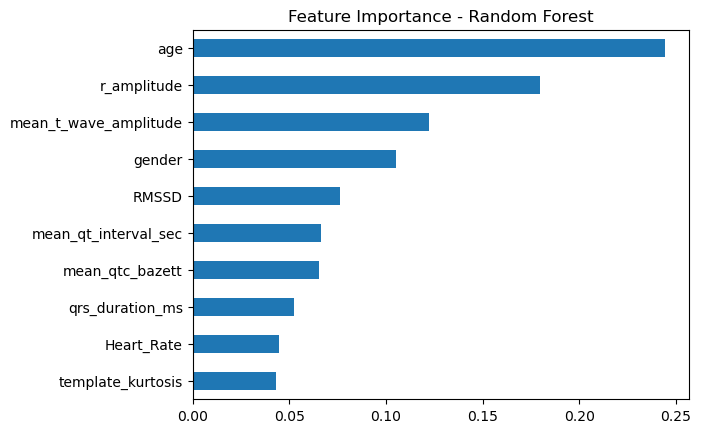

In [21]:
# Feature Importance for Random Forest
feat_importances = pd.Series(rf_best.feature_importances_, index=X.columns)
feat_importances.nlargest(10).plot(kind='barh', title='Feature Importance - Random Forest')
plt.gca().invert_yaxis()
plt.show()

The Random Forest effectively combines patient demographics (Age) with morphological changes (R-peaks, T-waves) and non-linear rhythm dynamics (RMSSD). This multi-faceted approach explains why it generally outperforms simpler linear models that fail to integrate these distinct feature types.

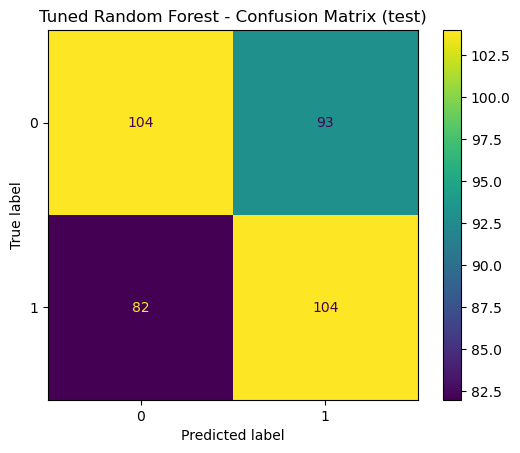


Tuned Random Forest Classification report (test):
                  precision    recall  f1-score   support

Non-ischemic (0)       0.56      0.53      0.54       197
    Ischemic (1)       0.53      0.56      0.54       186

        accuracy                           0.54       383
       macro avg       0.54      0.54      0.54       383
    weighted avg       0.54      0.54      0.54       383



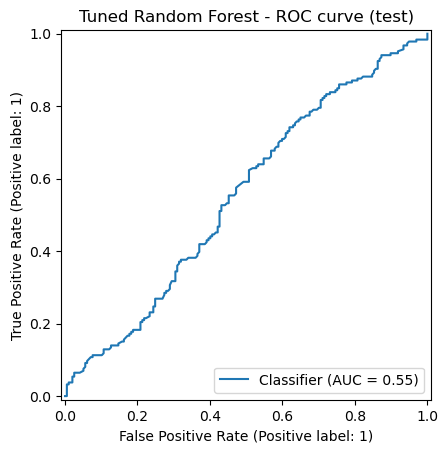

In [22]:
# Confusion matrix (test)
cm_rf = confusion_matrix(y_test, rfb_y_test_pred, labels=[0, 1])
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=[0, 1])
disp_rf.plot()
plt.title("Tuned Random Forest - Confusion Matrix (test)")
plt.show() 
print("\nTuned Random Forest Classification report (test):")
print(classification_report(y_test, rfb_y_test_pred, target_names=["Non-ischemic (0)", "Ischemic (1)"]))
# ROC curve (test)
RocCurveDisplay.from_predictions(y_test, rfb_y_test_proba)
plt.title("Tuned Random Forest - ROC curve (test)")
plt.show()


The Tuned Random Forest classifier was evaluated on a test set consisting of 383 instances, with a balanced distribution between Non-ischaemic ($n=197$) and Ischaemic ($n=186$) classes. The model achieved an overall accuracy of 0.54, which indicates a limited ability to differentiate between the two classes. Despite hyperparameter tuning, the performance metrics suggest that the model performs only marginally better than a random baseline, presenting significant challenges for deployment in a diagnostic capacity. A critical deficiency is noted in the sensitivity of the Ischaemic class, which stands at 0.56. This translates to a False Negative Rate of 44\%, meaning nearly half of the positive cases in the test set were misclassified as Non-ischaemic. In a clinical context, this lack of sensitivity poses a substantial risk, as it can lead to missed diagnoses. The precision for the Ischaemic class is 0.53, indicating a 47\% False Positive Rate among the predicted positive cases. While this is less critical than missed diagnoses, the low precision undermines the reliability of positive flags, potentially resulting in unnecessary follow-up procedures for healthy individuals. The F1-score for the positive class is 0.54, reflecting a poor balance between precision and recall. This metric confirms that the model struggles to capture the complexity of the feature space necessary for effectively isolating Ischaemic instances.

### ROC curves comparison

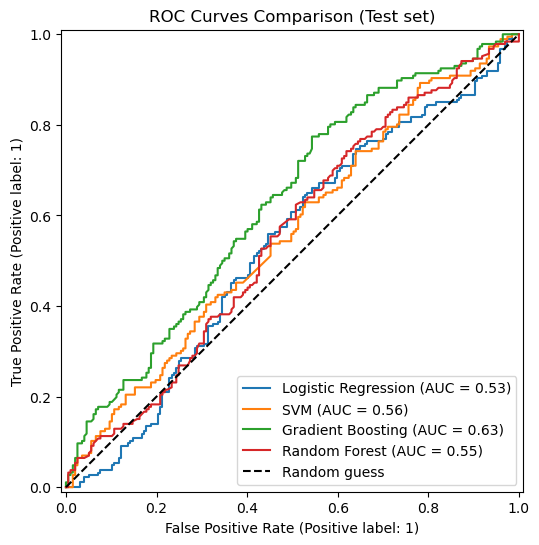

In [23]:

fig, ax = plt.subplots(figsize=(7, 6))

RocCurveDisplay.from_predictions(
    y_test, y_test_proba,
    name="Logistic Regression",
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_test, y_test_proba_svm,
    name="SVM",
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_test, gb_y_test_proba,
    name="Gradient Boosting",
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_test, rfb_y_test_proba,
    name="Random Forest",
    ax=ax
)

ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.set_title("ROC Curves Comparison (Test set)")
ax.legend()
plt.show()


The image presents a Receiver Operating Characteristic (ROC) curve comparison for four machine learning models evaluated on a test set. The x-axis shows the False Positive Rate (1 − Specificity), and the y-axis shows the True Positive Rate (Sensitivity). A dashed diagonal black line represents a random classifier (AUC = 0.50), which serves as the baseline for no predictive skill.
Model Performance (Legend) The legend lists the models in descending order of their Area Under the Curve (AUC) scores, which measure their overall ability to distinguish between classes:
- **Gradient Boosting** (green line), AUC = 0.63: This model achieves the best performance among the four. Its curve bends most prominently toward the top-left corner, indicating a more favorable balance between sensitivity and specificity than the other models.
- **SVM** (orange line), AUC = 0.56: The Support Vector Machine performs slightly better than random chance but remains relatively close to the diagonal.
- **Random Forest** (red line), AUC = 0.55: This model’s performance is comparable to that of the SVM and only marginally better than the random baseline, indicating limited predictive capability.
- **Logistic Regression** (blue line), AUC = 0.53: This is the lowest-performing model. Its curve lies close to the diagonal, suggesting it offers minimal improvement over random guessing in discriminating between classes.

## Time series motifs

In [24]:
from scipy.stats import skew
from scipy.stats import kurtosis
# Get the profile matrices of each patient
fs = 500
features_list = []
profile_matrices = []
patient_beats = {}
patient_anomalies = {}

m = int(0.8 * fs)

# Ensure m is defined (e.g., m = 200 for typical heartbeat length at 100Hz)
# m = 200 

for subject_id, data in df.groupby('subject_id'):
    # Ensure signal is float for precision
    signal = np.array(data['smoothed_V5'].iloc[0], dtype=np.float64)

    if len(signal) < m:
        print(f"Signal for subject {subject_id} is shorter than m={m}. Skipping.")
        continue

    # 1. Compute Matrix Profile
    profile = stumpy.stump(signal, m)

    # 2. Get Top Motifs (The "Representative Beats")
    # We increase max_motifs to capture the repeating rhythm
    motif_distances, motif_indices = stumpy.motifs(signal, profile[:, 0], max_motifs=5, min_neighbors=3)
    
    # Store the location of the best motif (most common beat shape)
    if len(motif_indices) > 0:
        best_motif_idx = motif_indices[0][0]
        patient_beats[subject_id] = motif_indices[0]
        
        # Extract the actual waveform of the "Standard Beat" for this patient
        representative_beat = signal[best_motif_idx : best_motif_idx + m]
    else:
        # Fallback if no motif found (rare)
        best_motif_idx = 0
        representative_beat = signal[0:m]


    # 3. Anomaly detection (Discords)
    discord_indices = np.argpartition(profile[:, 0], -3)[-3:]
    discord_indices = discord_indices[np.argsort(profile[discord_indices, 0])[::-1]]
    discord_scores = profile[discord_indices, 0]
    patient_anomalies[subject_id] = list(zip(discord_indices, discord_scores))

    # 4. Features Extraction
    P = profile[:, 0].astype(np.float64)
    gap_padding = np.full(m - 1, np.nan)

    P_padded = np.concatenate((P, gap_padding))
    
    #Save gapped profile if needed
    profile_matrices.append(P_padded)

    I = profile[:, 1]
    
    # --- Helper: Ischemia usually depresses/elevates the ST segment ---
    # We estimate the "ST area" by looking at the last 30% of the representative beat
    # (assuming the beat is centered or starts with P-wave)
    st_segment_window = representative_beat[int(0.7 * m):] 

    features = {
        'subject_id': subject_id,
        
        # ==========================================
        # 1. MATRIX PROFILE FEATURES (Shape/Anomaly)
        # ==========================================
        'mp_min': np.min(P),       # How perfect is the best match?
        'mp_max': np.max(P),       # How distinct is the worst anomaly?
        'mp_mean': np.mean(P),     # General signal noise/irregularity
        'mp_std': np.std(P),       # Variability in beat shapes
        'mp_skew': skew(P),        # Distribution of matching difficulty
        'num_anomalies': np.sum(P > (np.mean(P) + 2*np.std(P))),

        # ==========================================
        # 2. ISCHEMIA SPECIFIC FEATURES (Morphology)
        # ==========================================
        # A. Global Signal Statistics
        # Ischemia (ST depression) often creates a "tail" in the voltage distribution
        'signal_skew': skew(signal),     
        'signal_kurtosis': kurtosis(signal),
        
        # B. Representative Beat Analysis (The "Motif")
        # Ischemia alters the voltage energy of the beat
        'beat_energy': np.sum(representative_beat**2),
        'beat_complexity': np.std(representative_beat), # Flatter beats (T-wave inversion) have lower std
        'beat_range': np.ptp(representative_beat),      # Peak-to-Peak amplitude

        # C. ST-Segment Proxies (Crucial for Ischemia)
        # Compare the ST-segment mean to the beat's global mean
        'st_deviation': np.mean(st_segment_window) - np.mean(representative_beat),
        'st_energy': np.sum(st_segment_window**2),
        
        # ==========================================
        # 3. RHYTHM & HRV FEATURES
        # ==========================================
        # A. Profile-based rhythm
        'avg_neighbor_dist': np.mean(np.abs(I - np.arange(len(I)))),
        
        # B. Motif-based HRV (Heart Rate Variability)
        # Calculate time distance between occurrences of the SAME motif
        # This approximates the RR-interval stability.
        
    }

    # Add HRV feature if we found enough motif neighbors
    if len(motif_indices) > 0 and len(motif_indices[0]) > 1:
        # Sort indices to find sequential occurrences
        sorted_beats = np.sort(motif_indices[0])
        # Differences between beats (RR intervals)
        rr_intervals = np.diff(sorted_beats)
        
        features['est_hr_mean'] = np.mean(rr_intervals) # Proxy for Heart Rate
        features['est_hrv_std'] = np.std(rr_intervals)  # Proxy for HRV (SDNN)
    else:
        features['est_hr_mean'] = 0
        features['est_hrv_std'] = 0

    features_list.append(features)




profile_matrices = np.array(profile_matrices)
profile_matrices.shape
    

(1184, 5000)

In [25]:
features_df = pd.DataFrame(features_list)
# Add the ischemic labels
features_df = features_df.merge(
    labels_df[["subject_id", "label_ischemic"]],
    on="subject_id",
    how="inner"
)

features_df

,subject_id,mp_min,mp_max,mp_mean,mp_std,mp_skew,num_anomalies,signal_skew,signal_kurtosis,beat_energy,beat_complexity,beat_range,st_deviation,st_energy,avg_neighbor_dist,est_hr_mean,est_hrv_std,label_ischemic
0,10000980,2.8545368502076336,16.646937892307818,7.057208584880911,3.033254097507982,0.685325,197,0.284405,0.560149,357.600289,0.944997,4.403308,-0.014098,1.308332,1978.9769615301022,529.750000,51.960923,1
1,10004457,0.5720813069215579,2.501796395109156,1.0544076942790417,0.38440961823708625,1.149431,231,3.196636,11.484283,274.154531,0.827813,6.111266,-0.068137,3.777914,1487.245816126929,402.888889,144.102930,0
2,10007058,1.7010339578486775,23.04360641556604,4.207746926349513,3.2306929711571186,2.042622,289,-0.528139,12.470619,313.154347,0.884786,8.450218,-0.060614,1.550744,1720.5498804607694,517.375000,11.444841,1
3,10018684,4.503068478206746,11.49903011043636,6.892995927772236,1.323374780858131,0.178201,75,-1.778723,3.497584,399.570358,0.999427,4.710353,0.051217,187.584370,1068.650945446642,476.777778,264.227502,0
4,10044096,2.4761571688734163,19.191593947256774,5.637425385432571,4.236954342521575,1.617030,474,2.148842,29.137197,177.273374,0.665603,4.522852,-0.093754,2.222945,1524.5344490328189,518.125000,132.330493,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1179,19969326,2.4052542781182424,18.74333929727159,7.989649062643871,3.8665542922278373,0.885030,251,1.151578,2.977999,207.920764,0.719299,4.487191,0.141114,25.772947,1343.6187785264074,371.000000,191.369335,0
1180,19969991,3.107818404593259,7.195634313613566,4.077292811529399,0.5116518704529301,1.126529,134,-0.441723,0.188281,371.321923,0.962088,4.443980,0.476302,120.601462,1438.6807215822648,385.222222,200.757332,0
1181,19970101,3.9964626273805886,13.8300542209856,7.420954897292109,2.4547243397727057,0.518651,67,-0.473279,2.337561,398.901552,0.998518,6.567536,-0.103302,21.243861,1360.6622473375353,415.222222,114.539443,1
1182,19985259,1.5777390939325577,19.73606938619361,5.300696990764639,4.165917599655361,1.325829,312,2.339079,10.199862,340.195232,0.921709,6.881351,-0.180450,47.832811,1375.2260378178657,463.333333,142.383676,0


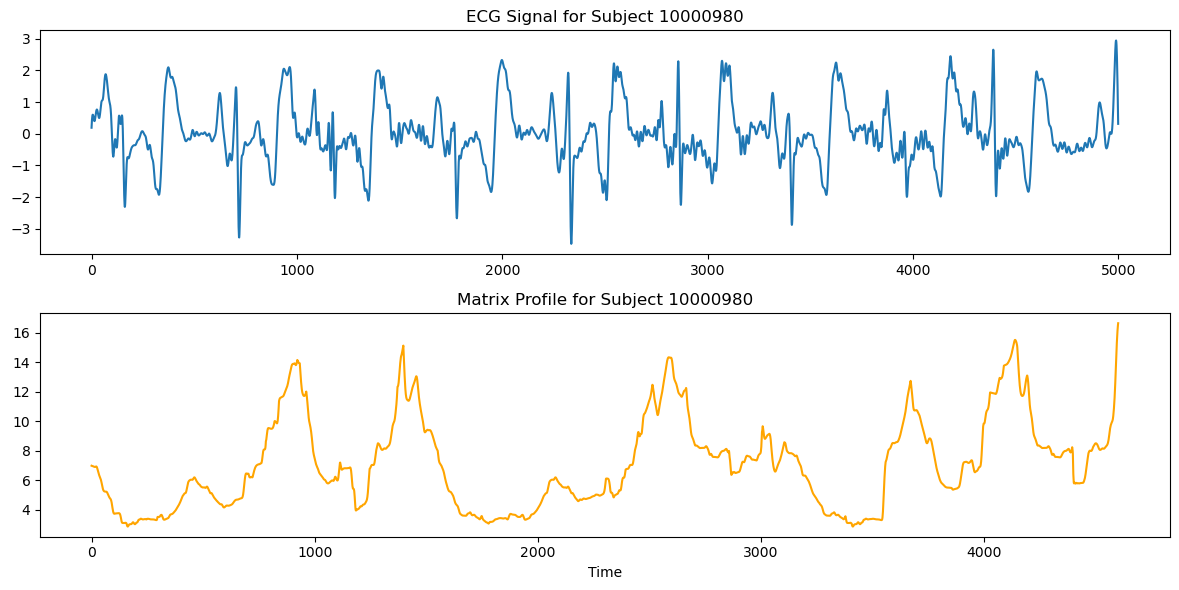

In [26]:
# plot the Matrix Profile directly under your ECG signal for the first patient
subject_id = df['subject_id'].iloc[0]
signal = np.array(df[df['subject_id'] == subject_id]['smoothed_V5'].iloc[0], dtype=np.float64)
profile = profile_matrices[0, :len(signal) - m + 1]
plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 1)
plt.plot(signal)
plt.title(f"ECG Signal for Subject {subject_id}")
plt.subplot(2, 1, 2)
plt.plot(profile, color='orange')
plt.title(f"Matrix Profile for Subject {subject_id}")
plt.xlabel("Time")
plt.tight_layout()
plt.show()

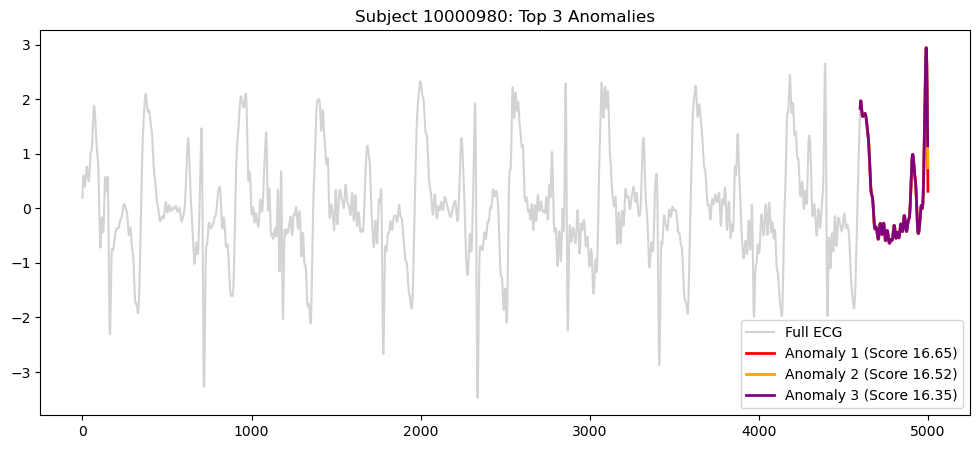

In [27]:
# Visualize the top 3 anomalies for one specific patient
subject_to_plot = list(patient_beats.keys())[0] # Just pick the first patient
discords = patient_anomalies[subject_to_plot]  # List of (idx, score) tuples

# Retrieve that patient's signal again for plotting
signal = df[df['subject_id'] == subject_to_plot]['smoothed_V5'].iloc[0]

plt.figure(figsize=(12, 5))
plt.plot(signal, color='lightgray', label="Full ECG")

# Highlight the top 3 anomalies in different colors
colors = ['red', 'orange', 'purple']
for i, (idx, score) in enumerate(discords):
    plt.plot(range(idx, idx+m), signal[idx : idx+m], color=colors[i % len(colors)], linewidth=2, label=f"Anomaly {i+1} (Score {score:.2f})")

plt.title(f"Subject {subject_to_plot}: Top 3 Anomalies")
plt.legend()
plt.show()

The clustering of all three top anomalies at the very end of the signal suggests that the model identified a single, major irregular event rather than scattered issues. The morphology of this event—a sudden, extreme vertical spike that breaks the pattern of the previous heartbeats—differs significantly from the earlier periodic rhythm.

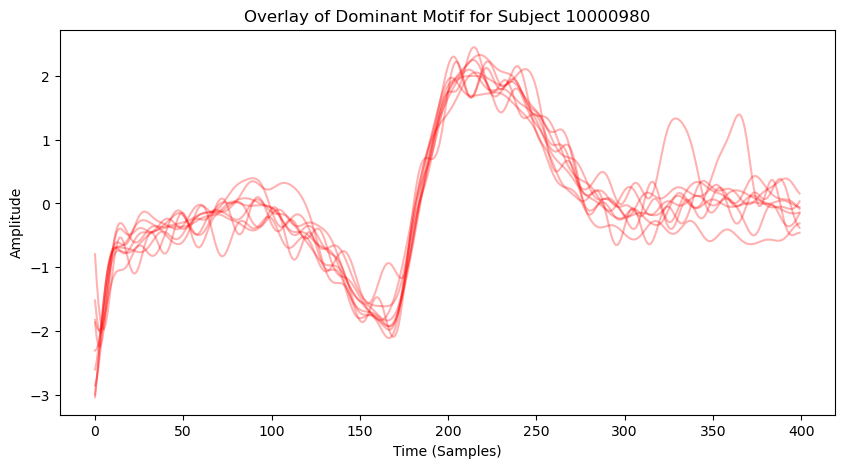

In [28]:
indices = patient_beats[subject_to_plot]
plt.figure(figsize=(10, 5))
plt.title(f"Overlay of Dominant Motif for Subject {subject_to_plot}")

# Loop through every index found and plot that segment
for idx in indices:
    # Ensure we don't go out of bounds
    if idx + m < len(signal):
        plt.plot(signal[idx : idx+m], color='red', alpha=0.3) # alpha makes them transparent

plt.xlabel("Time (Samples)")
plt.ylabel("Amplitude")
plt.show()

In [29]:
# Run a random forest classifier on the extracted features
TARGET = "label_ischemic"
X_feat = features_df.drop(columns=[TARGET, 'subject_id'])
y_feat = features_df[TARGET].astype(int)

# Split into train and test sets
Xf_train, Xf_test, yf_train, yf_test = train_test_split(
    X_feat, y_feat,
    test_size=0.30,
    stratify=y_feat,
    random_state=42
)

# Normalize features
scaler_feat = StandardScaler()
Xf_train = scaler_feat.fit_transform(Xf_train)
Xf_test = scaler_feat.transform(Xf_test)

param_dist = {
    "n_estimators": [30, 50, 100],
    "max_depth": [2, 4, 6, 8, None],
    "max_features": [2, 3, "sqrt"],
    "min_samples_split": randint(2, 20),
    "min_samples_leaf": randint(5, 20),
    "bootstrap": [True],
    "criterion": ["gini", "entropy"],
    "class_weight": ["balanced", None]
}

In [30]:
rf_base = RandomForestClassifier(random_state=42)

rf_search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_dist,
    n_iter=30,
    scoring="balanced_accuracy",
    cv=5,
    n_jobs=-1,
    random_state=42
)

rf_search.fit(X_train, y_train)

print("Best parameters found:")
print(rf_search.best_params_)

Best parameters found:
{'bootstrap': True, 'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 2, 'max_features': 'sqrt', 'min_samples_leaf': 9, 'min_samples_split': 16, 'n_estimators': 50}


In [31]:
rf_best = rf_search.best_estimator_

rf_best.fit(Xf_train, yf_train)

rf_best_results, (rfb_y_train_pred, rfb_y_test_pred,
                  rfb_y_train_proba, rfb_y_test_proba) = evaluate_binary(
    rf_best, Xf_train, yf_train, Xf_test, yf_test
)

pd.Series(rf_best_results).sort_index()

test_accuracy              0.536517
test_balanced_accuracy     0.540494
test_f1                    0.588529
test_precision             0.517544
test_recall                0.682081
test_roc_auc               0.514988
train_accuracy             0.585749
train_balanced_accuracy    0.590901
train_f1                   0.643080
train_precision            0.552773
train_recall               0.768657
train_roc_auc              0.639560
dtype: float64

In [32]:
rf_baseline = rf_base
rf_baseline.fit(Xf_train, yf_train)

rf_base_results, _ = evaluate_binary(
    rf_baseline, Xf_train, yf_train, Xf_test, yf_test
)

comparison_rf = pd.DataFrame({
    "Baseline RF (Features)": rf_base_results,
    "Tuned RF (Features)": rf_best_results
})

comparison_rf.sort_index()

,Baseline RF (Features),Tuned RF (Features)
test_accuracy,0.533708,0.536517
test_balanced_accuracy,0.532392,0.540494
test_f1,0.502994,0.588529
test_precision,0.521739,0.517544
test_recall,0.485549,0.682081
test_roc_auc,0.569396,0.514988
train_accuracy,1.000000,0.585749
train_balanced_accuracy,1.000000,0.590901
train_f1,1.000000,0.643080
train_precision,1.000000,0.552773


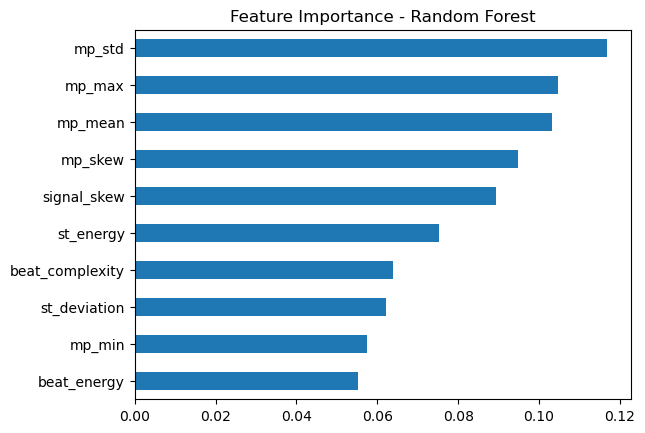

In [33]:
feat_importances = pd.Series(rf_best.feature_importances_, index=X_feat.columns)
feat_importances.nlargest(10).plot(kind='barh', title='Feature Importance - Random Forest')
plt.gca().invert_yaxis()
plt.show()

The Random Forest model prioritizes signal complexity over traditional clinical markers. Matrix Profile statistics dominate the decision process, with mp_std (variability), mp_max, and mp_mean occupying the top three spots. This indicates that the model relies primarily on the structural dissimilarity between heartbeats to detect ischemia. Distributional asymmetry also plays a key role, as evidenced by the high ranking of mp_skew and signal_skew. Notably, classic physiological indicators like st_energy and st_deviation are less influential, appearing lower in the hierarchy than these global complexity metrics.

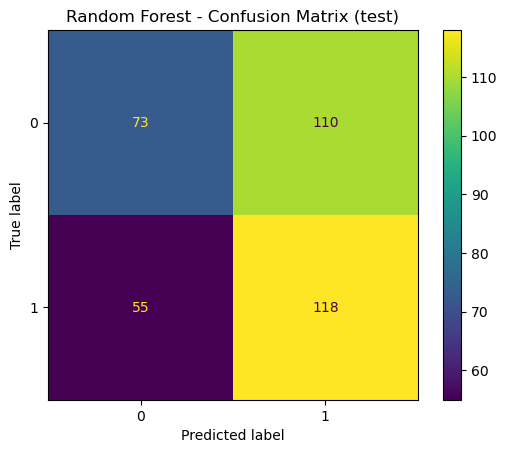


Classification report (test):
                  precision    recall  f1-score   support

Non-ischemic (0)       0.57      0.40      0.47       183
    Ischemic (1)       0.52      0.68      0.59       173

        accuracy                           0.54       356
       macro avg       0.54      0.54      0.53       356
    weighted avg       0.54      0.54      0.53       356



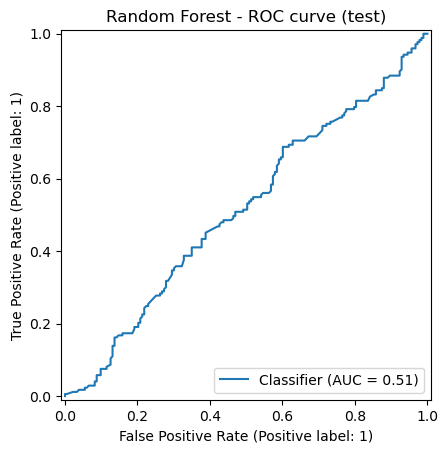

In [34]:
# Confusion matrix (test)
cm_rf = confusion_matrix(yf_test, rfb_y_test_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=[0, 1])
disp.plot()
plt.title("Random Forest - Confusion Matrix (test)")
plt.show()

print("\nClassification report (test):")
print(classification_report(
    yf_test, rfb_y_test_pred,
    target_names=["Non-ischemic (0)", "Ischemic (1)"]
))

# ROC curve (test)
RocCurveDisplay.from_predictions(yf_test, rfb_y_test_proba)
plt.title("Random Forest - ROC curve (test)")
plt.show()

The model achieved an overall accuracy of $54\%$. In a binary classification task with a nearly balanced dataset ($51.4\%$ Class 0 vs. $48.6\%$ Class 1), a random guess would be expected to achieve an accuracy of approximately $50\%$. A result of $0.54$ suggests that the model has marginally surpassed the random baseline, showing a slight improvement in predictive capability compared to previous iterations. For the Ischaemic class (1), the model correctly identifies $68\%$ of the positive cases (Recall). This is a notable shift in behaviour, reducing the False Negative rate to $32\%$. However, this sensitivity comes at a cost: the Precision remains low at $0.52$, meaning that when the model flags a case as Ischaemic, it is incorrect $48\%$ of the time. The F1-Score of $0.59$ reflects this aggressive prediction strategy—the model captures more true cases but generates a high volume of false alarms. Performance for the negative class (Non-ischaemic) has suffered inversely. While the Precision is slightly higher at $0.57$, the Recall has dropped significantly to $0.40$. This indicates that the model now struggles to correctly identify healthy patients, misclassifying $60\%$ of true healthy signals as pathological. Effectively, the classifier has biased itself toward predicting "Ischaemia," improving safety (sensitivity) at the expense of specificity.

## Time series shaplets Classification

In [35]:
# Get dataset dimensions
n_ts, ts_sz = clf_df.shape[0], clf_df['smoothed_V5'].iloc[0].shape[0]
n_classes = clf_df['label_ischemic'].nunique()

In [36]:
from sklearn.model_selection import train_test_split
from tslearn.preprocessing import TimeSeriesScalerMeanVariance

# Prepare data for time-series classification
X = np.array(clf_df['smoothed_V5'].tolist())
y = np.array(clf_df['label_ischemic'].tolist())

# Reshape X to have a third dimension (n_samples, n_timesteps, n_features)
X = X.reshape(X.shape[0], X.shape[1], 1)


print(f"Original Shape: {X.shape}")
X = X[:, :1500, :]
print(f"New Shape (Time Sliced): {X.shape}") 

# Split into train and test sets with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Original Shape: (1276, 5000, 1)
New Shape (Time Sliced): (1276, 1500, 1)


In [37]:
# Scale the data
scaler = TimeSeriesScalerMeanVariance()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [38]:
# Get the sampling rate from the data
sampling_rate_hz = 500 
shapelet_sizes = {
    20: 50,    # QRS Complex (40ms: sharp, distinctive)
    50: 30,    # P-Wave (100ms: atrial depolarization)
    100: 20,   # T-Wave (200ms: ventricular repolarization)
    200: 10,   # QT Interval (400ms: complete ventricular cycle)
}

print("Optimized ECG Sizes:", shapelet_sizes)

Optimized ECG Sizes: {20: 50, 50: 30, 100: 20, 200: 10}


To classify the time series we use the LearningShapelets classifier, using the "Adam" optimizer.

The Adam optimizer is particularly effective for LearningShapelets because it addresses the main difficulties in optimizing shapelet parameters:
- Adaptive learning rates: Shapelets (subsequences) and classification weights can differ greatly in scale. Adam assigns a separate learning rate to each parameter, which helps prevent vanishing gradients that commonly affect shapelet learning.
- Faster convergence: By combining the momentum of SGD with the adaptive scaling of RMSProp, Adam moves through the complex, non-convex loss landscape more efficiently, often requiring fewer epochs to discover discriminative shapelets.
- Stability: Adam is less sensitive to the choice of initial learning rate and better handles the noisy gradients produced by sliding-window distance calculations than standard SGD.

In [39]:
# Create the LearningShapelets classifier
shp_clf = LearningShapelets(n_shapelets_per_size=shapelet_sizes,
                        optimizer="adam",
                        weight_regularizer=.01,
                        max_iter=1000,
                        random_state=42,
                        verbose=1)

In [40]:
# Fit the shapelet model
shp_clf.fit(X_train, y_train)

/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/site-packages/tslearn/shapelets/shapelets.py:492: FutureWarning: The default value for 'scale' is set to False in version 0.4 to ensure backward compatibility, but is likely to change in a future version.
  warnings.warn("The default value for 'scale' is set to False "
/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/site-packages/keras/src/layers/layer.py:970: UserWarning: Layer 'min_pooling_0' (of type GlobalMinPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/site-packages/keras/src/layers/layer.py:970: UserWarning: Layer 'min_pooling_1' (of type GlobalMinPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers wi

Epoch 1/1000


/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/site-packages/keras/src/layers/layer.py:970: UserWarning: Layer 'min_pooling_3' (of type GlobalMinPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/site-packages/keras/src/layers/layer.py:970: UserWarning: Layer 'min_pooling_0' (of type GlobalMinPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/site-packages/keras/src/layers/layer.py:970: UserWarning: Layer 'min_pooling_1' (of type GlobalMinPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the

4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 403ms/step - binary_accuracy: 0.5157 - binary_crossentropy: 0.7537 - loss: 0.7749
Epoch 2/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 403ms/step - binary_accuracy: 0.5059 - binary_crossentropy: 0.7133 - loss: 0.7344
Epoch 3/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 399ms/step - binary_accuracy: 0.5010 - binary_crossentropy: 0.7038 - loss: 0.7248
Epoch 4/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 398ms/step - binary_accuracy: 0.5059 - binary_crossentropy: 0.7066 - loss: 0.7273
Epoch 5/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 404ms/step - binary_accuracy: 0.5108 - binary_crossentropy: 0.7057 - loss: 0.7262
Epoch 6/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 395ms/step - binary_accuracy: 0.5167 - binary_crossentropy: 0.7010 - loss: 0.7213
Epoch 7/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 406ms/step - binary_accuracy: 0.5186 - binary_crossentropy: 0.6981 - loss: 0.7181
Epoch 8/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 403ms/step - binary_accuracy: 0.5127 - binary_crossentropy: 0.6982 - loss: 0.7180
Epoch 9/1000
4/4 ━━━━━━━━━━━━

,n_shapelets_per_size,"{20: 50, 50: 30, 100: 20, 200: 10}"
,max_iter,1000
,batch_size,256
,verbose,1
,optimizer,'adam'
,weight_regularizer,0.01
,shapelet_length,0.15
,total_lengths,3
,max_size,None
,scale,False
,random_state,42


In [41]:
from sklearn.metrics import accuracy_score
# Evaluate the shapelet classifier
predicted_labels = shp_clf.predict(X_test)
print("Correct classification rate:", accuracy_score(y_test, predicted_labels))
predicted_locations = shp_clf.locate(X)

/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/site-packages/keras/src/layers/layer.py:970: UserWarning: Layer 'min_pooling_0' (of type GlobalMinPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/site-packages/keras/src/layers/layer.py:970: UserWarning: Layer 'min_pooling_1' (of type GlobalMinPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/site-packages/keras/src/layers/layer.py:970: UserWarning: Layer 'min_pooling_2' (of type GlobalMinPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 449ms/step
Correct classification rate: 0.48828125
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 330ms/step


In [42]:
# Evaluate shapelet-based model
shp_results, (shp_y_train_pred, shp_y_test_pred,
              shp_y_train_proba, shp_y_test_proba) = evaluate_binary(
    shp_clf, X_train.reshape(X_train.shape[0], X_train.shape[1]),
    y_train,
    X_test.reshape(X_test.shape[0], X_test.shape[1]),
    y_test
)
pd.Series(shp_results).sort_index()

3/4 ━━━━━━━━━━━━━━━━━━━━ 0s 289ms/step

/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/site-packages/keras/src/layers/layer.py:970: UserWarning: Layer 'min_pooling_0' (of type GlobalMinPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/site-packages/keras/src/layers/layer.py:970: UserWarning: Layer 'min_pooling_1' (of type GlobalMinPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/site-packages/keras/src/layers/layer.py:970: UserWarning: Layer 'min_pooling_2' (of type GlobalMinPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 347ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 315ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 297ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 298ms/step


test_accuracy              0.488281
test_balanced_accuracy     0.486437
test_f1                    0.447257
test_precision             0.469027
test_recall                0.427419
test_roc_auc               0.505071
train_accuracy             0.554902
train_balanced_accuracy    0.554836
train_f1                   0.546906
train_precision            0.541502
train_recall               0.552419
train_roc_auc              0.587132
dtype: float64

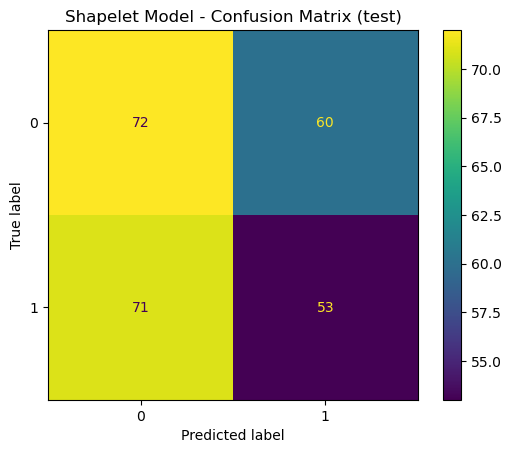


Shapelet Model Classification report (test):
                  precision    recall  f1-score   support

Non-ischemic (0)       0.50      0.55      0.52       132
    Ischemic (1)       0.47      0.43      0.45       124

        accuracy                           0.49       256
       macro avg       0.49      0.49      0.49       256
    weighted avg       0.49      0.49      0.49       256



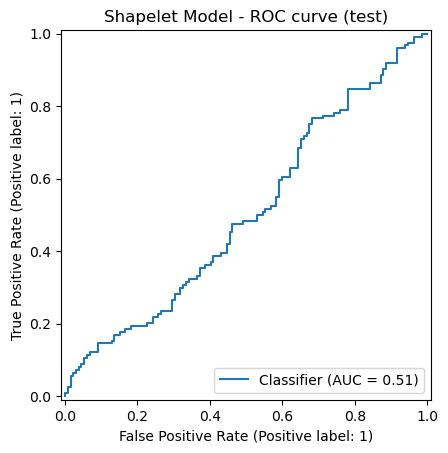

In [43]:
#Confusion matrix (test) for shapelet model
cm_shp = confusion_matrix(y_test, shp_y_test_pred, labels=[0, 1])
disp_shp = ConfusionMatrixDisplay(confusion_matrix=cm_shp, display_labels=[0, 1])
disp_shp.plot()
plt.title("Shapelet Model - Confusion Matrix (test)")
plt.show()

#Print classification report (test) for shapelet model
print("\nShapelet Model Classification report (test):")
print(classification_report(y_test, shp_y_test_pred, target_names=["Non-ischemic (0)", "Ischemic (1)"]))

#ROC curve (test) for shapelet model
RocCurveDisplay.from_predictions(y_test, shp_y_test_proba)
plt.title("Shapelet Model - ROC curve (test)")
plt.show()

The model achieved an overall accuracy of $49\%$, which is slightly below the performance of random guessing in a balanced binary classification task. This result indicates that the extracted shapelets—designed to capture local discriminative features such as QRS complexes or T-waves—failed to establish a valid separation boundary between the Ischaemic and Non-Ischaemic classes. For the Ischaemic class (1), the model correctly identified only $43\%$ of the positive cases (Recall = $0.43$). While this is an improvement over previous iterations where sensitivity was critically low ($34\%$), the classifier still misses more than half of the patients with pathology. Additionally, the Precision of $0.47$ reveals that when the model flags a patient as Ischaemic, the prediction is incorrect more often than not ($53\%$ false positive rate). The resulting F1-score of $0.45$ confirms that the model remains unreliable for clinical disease detection. In contrast to prior results where the model showed a strong bias toward the healthy class, the current performance is more symmetrical but equally poor. The Non-Ischaemic class (0) recall dropped to $55\%$, suggesting the model is no longer defaulting to the "healthy" label but is instead making inconsistent predictions across both groups. With a Precision of $0.50$ for the Non-Ischaemic class, the classifier essentially exhibits no predictive confidence, performing equivalently to a coin flip.

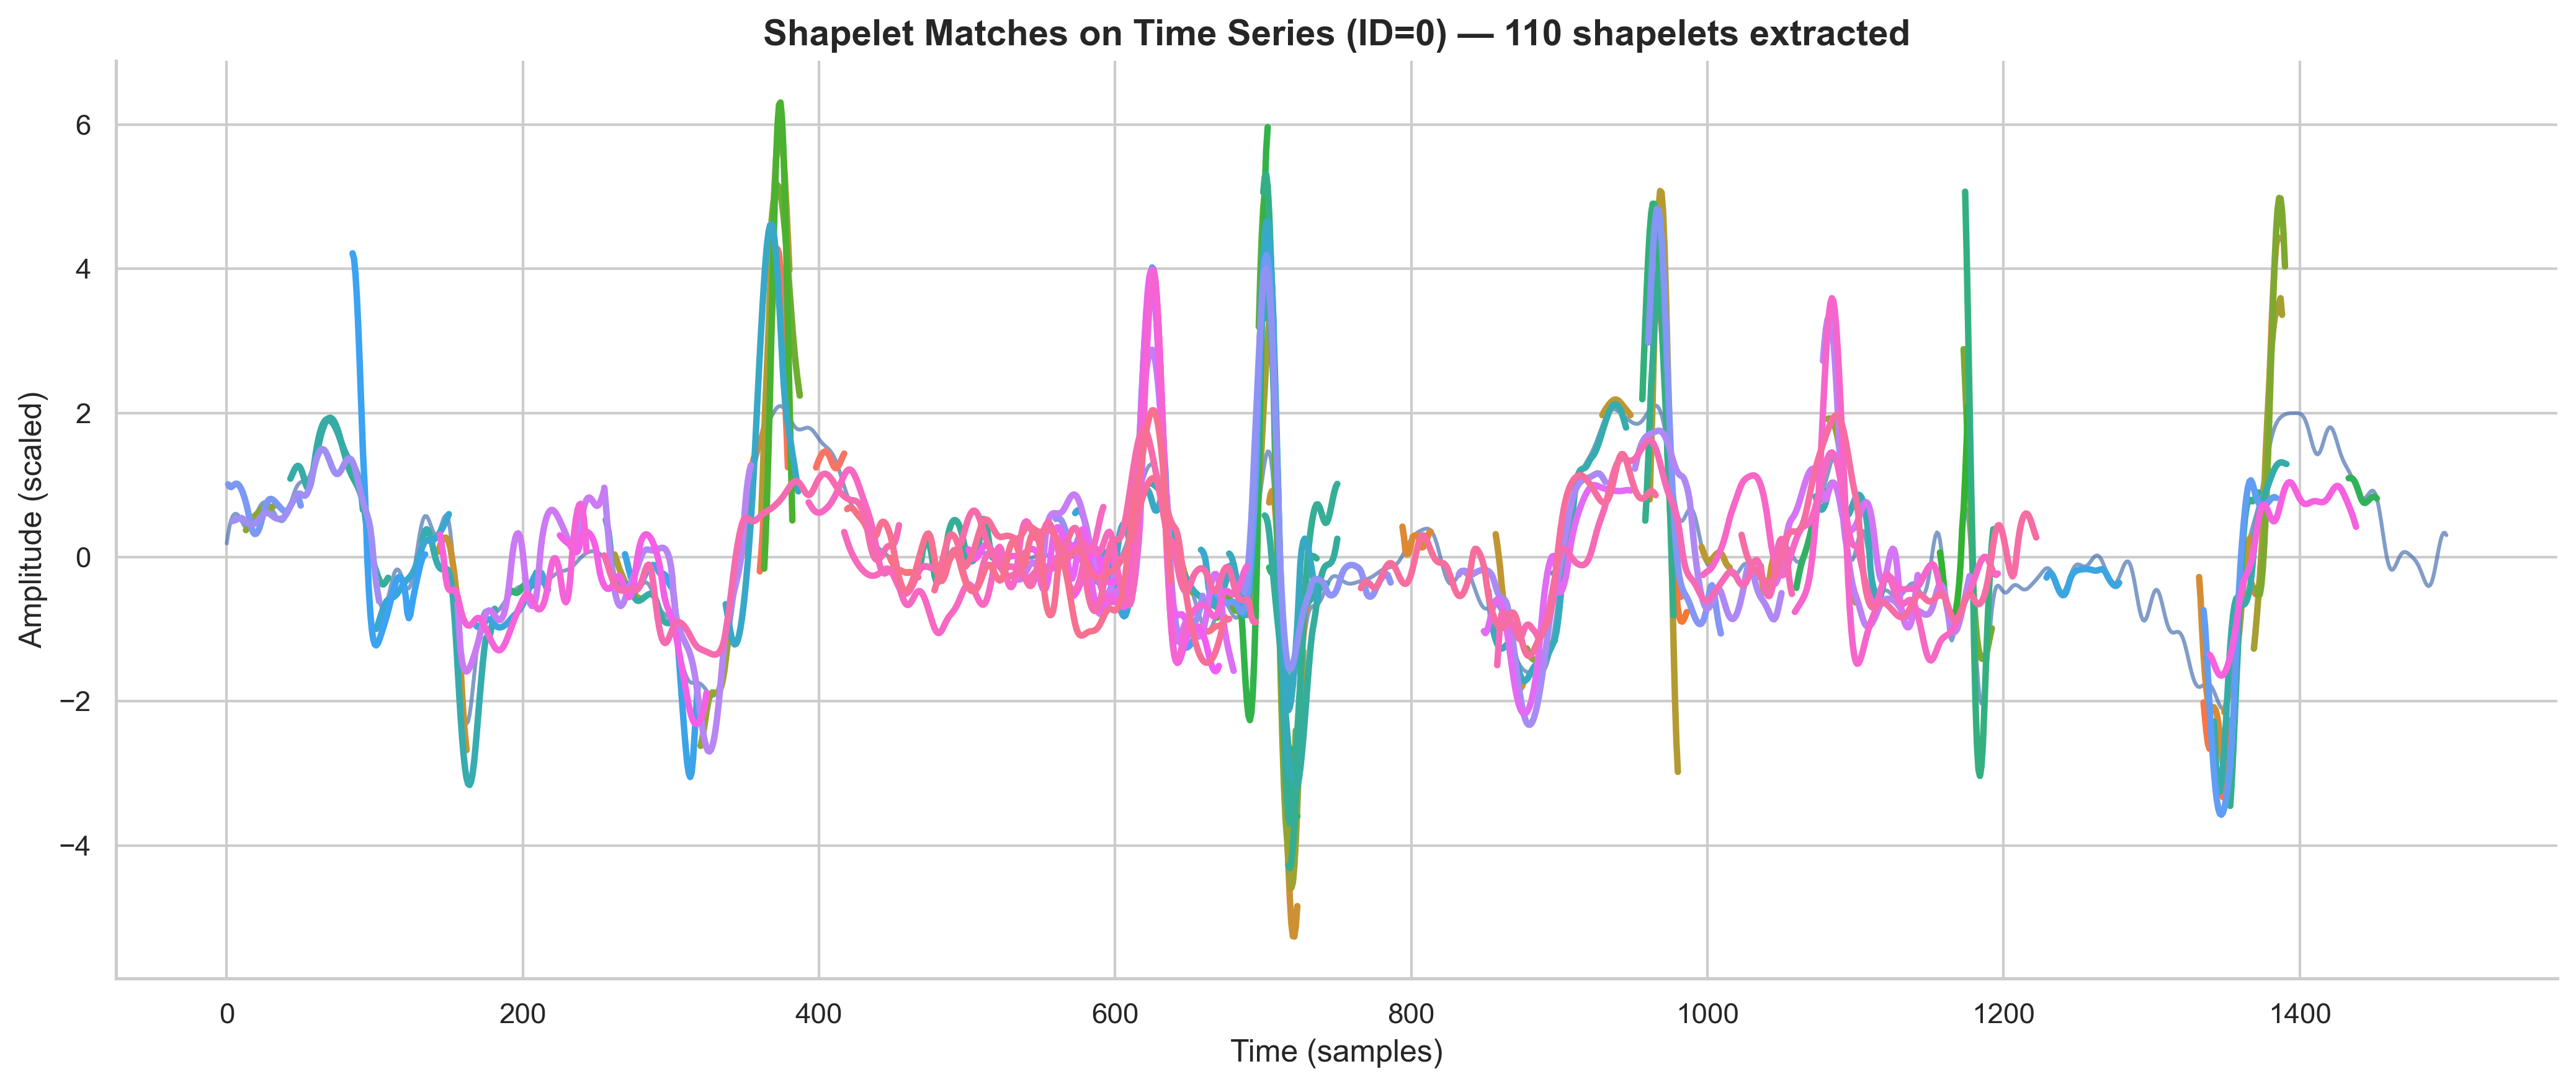

In [44]:
import seaborn as sns
import matplotlib.pyplot as plt

# Visualize shapelet matches on a specific time series
ts_id = 0
n_shapelets = sum(shapelet_sizes.values())

# Set seaborn style
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(14, 6), dpi=300)

# Plot the original time series
ax.plot(X[ts_id].ravel(), label='ECG Signal', color=sns.color_palette("deep")[0], alpha=0.7)

# Plot each shapelet at its matched location
colors = sns.color_palette("husl", n_colors=len(shp_clf.shapelets_))
for idx_shp, shp in enumerate(shp_clf.shapelets_):
    t0 = predicted_locations[ts_id, idx_shp]
    ax.plot(np.arange(t0, t0 + len(shp)), shp.ravel(), 
            linewidth=2.5, color=colors[idx_shp], 
            label=f'Shapelet {idx_shp + 1} (len={len(shp)})')

ax.set_title(f'Shapelet Matches on Time Series (ID={ts_id}) — {n_shapelets} shapelets extracted', 
             fontsize=14, fontweight='bold')
ax.set_xlabel('Time (samples)', fontsize=12)
ax.set_ylabel('Amplitude (scaled)', fontsize=12)


sns.despine()
plt.tight_layout()
plt.show()